# 02 - Business impact: *does a late delivery really hurt the customer experience?*

**Why this notebook exists.** A late-delivery model is only worth building if lateness *matters*.
Here we quantify how much a late delivery lowers the **review score** a customer leaves.

**The method in one paragraph.** We start with the raw gap between late and on-time orders, then
ask three progressively harder questions: (1) is the gap statistically real? (Mann-Whitney,
bootstrap), (2) does it survive after comparing like with like? (regression with controls, then
*within the same seller*), and (3) does it grow with the size of the delay? (dose-response). We
finish with a finding the raw numbers hide: **when** the customer reviewed.

**Wording discipline.** Everything below is an **adjusted association**, not a randomized causal
effect. We cannot run an experiment that delays random parcels; Section 8 lists what could still
bias the estimate.

**Reviews are an outcome we study here - they are never a model feature** (a review is written
after delivery, so using it to predict lateness would be leakage).

In [1]:
import warnings

warnings.filterwarnings("ignore")
import json
import pandas as pd
from IPython.display import Image, Markdown, display

from ontime.config import load_config, project_path
from ontime.analysis import impact

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
CFG = load_config()
FIG = project_path(CFG["paths"]["figures_dir"])
show = lambda name: display(Image(filename=str(FIG / name)))
pct = lambda v: f"{v:.1%}"
ci = lambda lo_hi, nd=2: f"[{lo_hi[0]:.{nd}f}, {lo_hi[1]:.{nd}f}]"

d = impact.build_analysis_frame()

## 1. Building the analysis table
Each order is joined to **one** review. Some customers revise their review (about 0.5% of orders
have two or three), so we keep the **latest** one - the customer's settled opinion - with a
deterministic tie-break. Orders without any review are dropped (there are very few).

In [2]:
n_orders = len(impact.load_orders() if hasattr(impact, "load_orders") else d)
Markdown(f"""
- Orders in the delivered/trimmed population: **{n_orders:,}**
- Orders with a usable review (analysis sample): **{len(d):,}** ({pct(len(d) / n_orders)})
- Late orders in the sample: **{int(d["is_late"].sum()):,}** ({pct(d["is_late"].mean())})
""")


- Orders in the delivered/trimmed population: **94,937**
- Orders with a usable review (analysis sample): **94,296** (99.3%)
- Late orders in the sample: **6,352** (6.7%)


## 2. The raw gap
**Question:** how different are the reviews of late and on-time orders, before any adjustment?

,orders,mean_score,median_score,share_1_star,share_1_or_2_star,share_5_star
is_late,,,,,,
on time,87944,4.287,5.000,0.066,0.093,0.621
late,6352,2.264,1.000,0.540,0.626,0.164


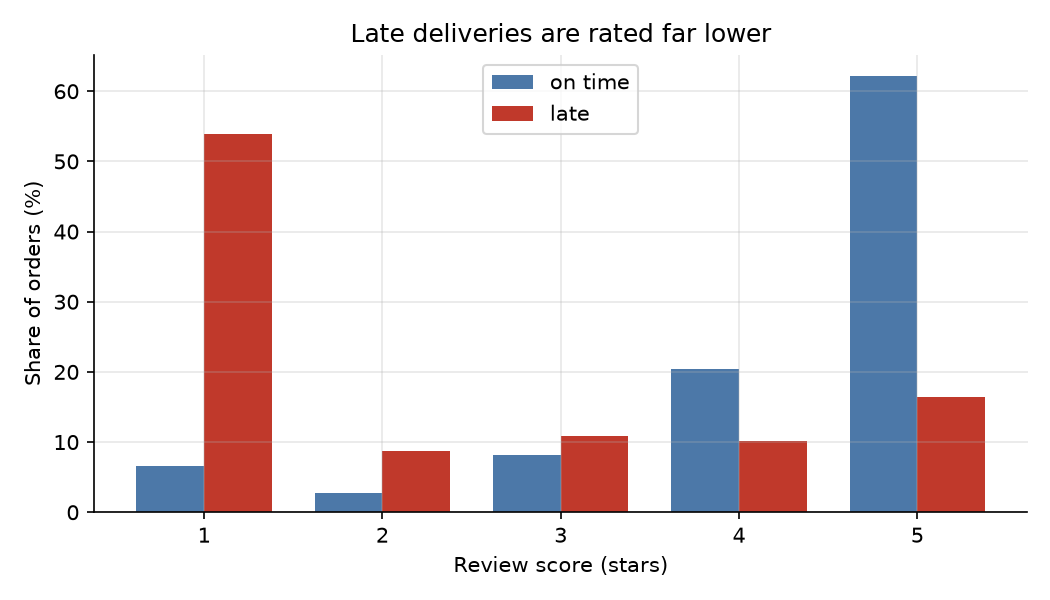


**Inference.** On-time orders average **4.29** stars; late orders
average **2.26** - a raw gap of **-2.02 stars**.
**54.0%** of late orders get the lowest possible rating (1 star),
versus **6.6%** of on-time orders.
The *median* late order is a 1-star review. Among late orders
the second most common rating is 5 stars (16.4%): some customers
do not mind, but the bulk are very unhappy - the penalty is concentrated in 1-star reviews rather
than spread evenly.


In [3]:
desc = impact.descriptive(d)
display(desc)
show("impact_score_distribution.png")
gap = desc.loc["late", "mean_score"] - desc.loc["on time", "mean_score"]
Markdown(f"""
**Inference.** On-time orders average **{desc.loc["on time", "mean_score"]:.2f}** stars; late orders
average **{desc.loc["late", "mean_score"]:.2f}** - a raw gap of **{gap:.2f} stars**.
**{pct(desc.loc["late", "share_1_star"])}** of late orders get the lowest possible rating (1 star),
versus **{pct(desc.loc["on time", "share_1_star"])}** of on-time orders.
The *median* late order is a {desc.loc["late", "median_score"]:.0f}-star review. Among late orders
the second most common rating is 5 stars ({pct(desc.loc["late", "share_5_star"])}): some customers
do not mind, but the bulk are very unhappy - the penalty is concentrated in 1-star reviews rather
than spread evenly.
""")

## 3. Is the gap statistically real?
Two complementary checks:

- **Mann-Whitney U test** - a rank test. We use it instead of a t-test because review scores are
  ordinal (1-5) and piled up at 5; a t-test assumes roughly normal data. Its effect size is
  easy to say out loud: *"if I pick one late and one on-time order at random, how often is the
  on-time order rated higher?"*
- **Bootstrap confidence intervals** - resample the data thousands of times and see how much the
  gap moves; no distributional assumptions.

In [4]:
mw = impact.mann_whitney(d)
bs = impact.bootstrap_differences(d, CFG["tuning"]["bootstrap_resamples"], CFG["seed"])
Markdown(f"""
**Mann-Whitney U.** p-value = **{mw["p_value"]:.2g}** (a value of exactly 0 here only means "smaller than
floating point can show").
In **{pct(mw["prob_ontime_scores_higher_than_late"])}** of random late/on-time pairs the on-time order has the
higher score (ties counted as half).

**Bootstrap ({bs["n_bootstrap"]:,} resamples).**
- Difference in mean score (late - on time): **{bs["mean_score_diff"]:.2f}**, 95% CI **{ci(bs["mean_score_diff_ci95"])}**
- Difference in share of 1-2 star reviews: **{bs["low_score_share_diff"] * 100:.1f} percentage points**,
  95% CI **{ci([x * 100 for x in bs["low_score_share_diff_ci95"]], 1)}**

**Inference.** The gap is not noise: the interval is tight and nowhere near zero. But this is
still a *raw* comparison - late orders may differ from on-time orders in other ways (farther,
different categories, different sellers). Next we try to compare like with like.
""")


**Mann-Whitney U.** p-value = **0** (a value of exactly 0 here only means "smaller than
floating point can show").
In **81.9%** of random late/on-time pairs the on-time order has the
higher score (ties counted as half).

**Bootstrap (1,000 resamples).**
- Difference in mean score (late - on time): **-2.02**, 95% CI **[-2.06, -1.98]**
- Difference in share of 1-2 star reviews: **53.3 percentage points**,
  95% CI **[52.2, 54.6]**

**Inference.** The gap is not noise: the interval is tight and nowhere near zero. But this is
still a *raw* comparison - late orders may differ from on-time orders in other ways (farther,
different categories, different sellers). Next we try to compare like with like.


## 4. Adjusting for other things (OLS regression)
We regress the review score on `is_late` plus controls: **log price, log freight, number of items,
log distance, same-state flag, product category group, customer state, and approval month**.

*Why these controls?* They are known at order time and plausibly affect both the chance of being
late and how satisfied the customer is (an expensive, far-away, bulky purchase is both slower and
more demanding). Standard errors are **clustered by seller**, because orders of one seller are
not independent of each other.

*Reading the coefficient:* the change in the expected star rating associated with being late,
holding the controls fixed.

In [5]:
ols = impact.ols_adjusted(d)
tbl = pd.DataFrame(
    {
        "model": ["raw (is_late only)", "with controls"],
        "late coefficient (stars)": [ols["unadjusted"]["coef"], ols["adjusted"]["coef"]],
        "95% CI low": [ols["unadjusted"]["ci95"][0], ols["adjusted"]["ci95"][0]],
        "95% CI high": [ols["unadjusted"]["ci95"][1], ols["adjusted"]["ci95"][1]],
    }
).set_index("model")
display(tbl)
Markdown(f"""
**Inference.** Adding controls moves the estimate from **{ols["unadjusted"]["coef"]:.2f}** to
**{ols["adjusted"]["coef"]:.2f}** stars (95% CI {ci(ols["adjusted"]["ci95"])}). The change is small, so
distance, price, category, region and season explain very little of the penalty. *Being late
itself* (or something tightly bound to it) carries almost all of it.
""")

,late coefficient (stars),95% CI low,95% CI high
model,,,
raw (is_late only),-2.023,-2.070,-1.976
with controls,-1.968,-2.016,-1.919



**Inference.** Adding controls moves the estimate from **-2.02** to
**-1.97** stars (95% CI [-2.02, -1.92]). The change is small, so
distance, price, category, region and season explain very little of the penalty. *Being late
itself* (or something tightly bound to it) carries almost all of it.


## 5. Robustness 1 - compare each seller with *themselves*
**Biggest worry:** some sellers are simply worse - slower **and** lower quality. Then "late"
would partly be a stand-in for "bad seller". The fix: use **seller fixed effects**, i.e. only
compare a seller's late orders with that *same seller's* on-time orders. Anything constant about
the seller (quality, products, brand) cancels out. Only sellers who have both late and
on-time orders contribute.

In [6]:
fe = impact.seller_fixed_effects(d)
Markdown(f"""
Within-seller estimate: **{fe["coef"]:.2f}** stars (95% CI {ci(fe["ci95"])}), using
**{fe["n_orders"]:,}** orders from **{fe["n_sellers"]:,}** sellers who have both late and on-time orders.

**Inference.** The within-seller estimate is {"very close to" if abs(fe["coef"] - ols["adjusted"]["coef"]) < 0.15 else "different from"} the
pooled one ({ols["adjusted"]["coef"]:.2f}). Seller quality that stays constant over time is therefore
**not** what drives the gap; the same seller is rated much lower on the orders that arrive late.
(It does not rule out *time-varying* seller problems - see Section 9.)
""")


Within-seller estimate: **-1.98** stars (95% CI [-2.03, -1.93]), using
**84,243** orders from **1,199** sellers who have both late and on-time orders.

**Inference.** The within-seller estimate is very close to the
pooled one (-1.97). Seller quality that stays constant over time is therefore
**not** what drives the gap; the same seller is rated much lower on the orders that arrive late.
(It does not rule out *time-varying* seller problems - see Section 9.)


## 6. Robustness 2 - treat the score as ordinal (ordered logit)
OLS treats the step 1->2 as equal to 4->5. An **ordered logit** only assumes the scores are
*ordered*. It reports an **odds ratio**: the multiplicative change in the odds of getting a
*higher* rating category when the order is late. An odds ratio below 1 means worse reviews.
(Fitted on a seeded random subsample for speed; sample size is shown.)

In [7]:
ol = impact.ordered_logit(d, seed=CFG["seed"])
Markdown(f"""
Odds ratio for late: **{ol["odds_ratio"]:.3f}** (95% CI {ci(ol["odds_ratio_ci95"], 3)}), n = {ol["n"]:,},
optimizer converged: **{ol["converged"]}**.

**Inference.** Late orders have **{(1 - ol["odds_ratio"]) * 100:.0f}% lower odds** of landing in a higher
review category. The conclusion matches OLS: a large, consistent penalty. The odds-ratio scale
exaggerates the *feel* of the effect (odds are not probabilities), which is why the star-scale
numbers are the ones we quote to a business audience.
""")


Odds ratio for late: **0.068** (95% CI [0.063, 0.074]), n = 40,000,
optimizer converged: **True**.

**Inference.** Late orders have **93% lower odds** of landing in a higher
review category. The conclusion matches OLS: a large, consistent penalty. The odds-ratio scale
exaggerates the *feel* of the effect (odds are not probabilities), which is why the star-scale
numbers are the ones we quote to a business audience.


## 7. Dose-response: does a bigger delay hurt more?
If lateness truly drives dissatisfaction, the penalty should **grow** with the delay and be
absent when orders arrive early. Here we bucket orders by the number of days between the
promised date and the actual delivery date.

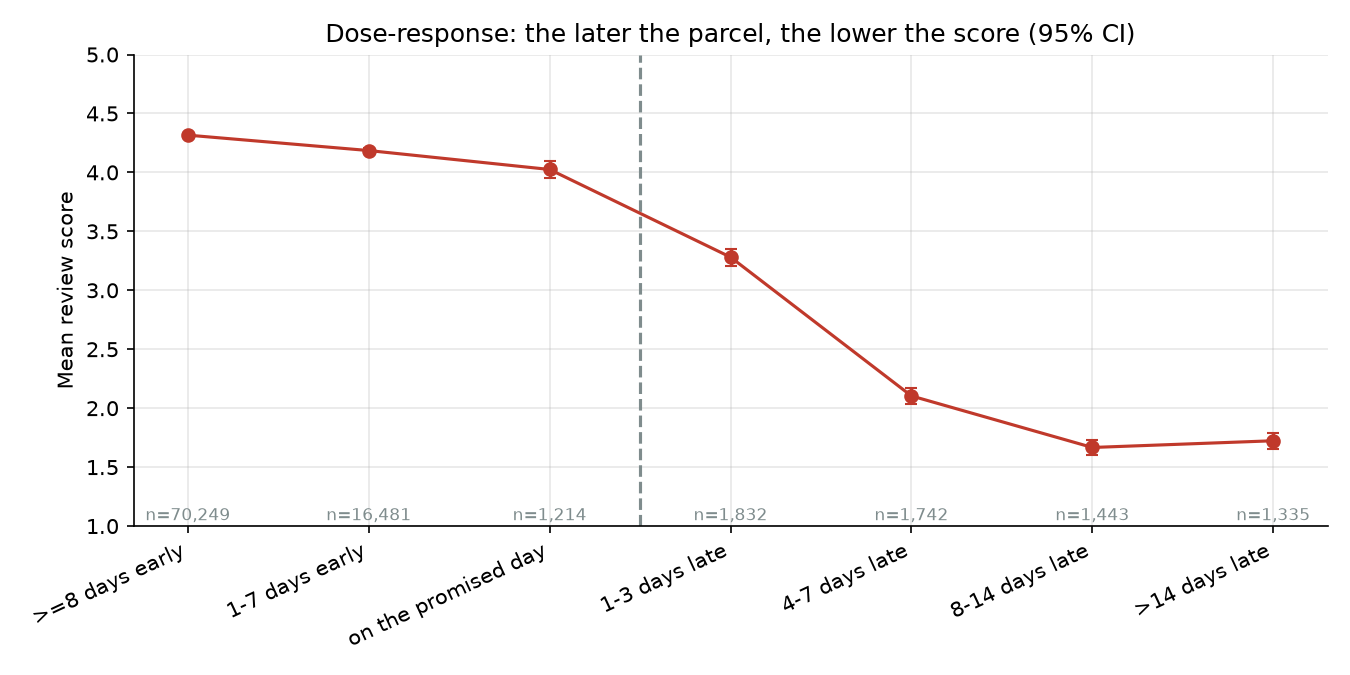

,timing,orders,mean_score,ci_low,ci_high,share_1_or_2_star
0,>=8 days early,70249,4.316,4.308,4.324,0.090
1,1-7 days early,16481,4.185,4.167,4.203,0.105
2,on the promised day,1214,4.025,3.954,4.095,0.125
3,1-3 days late,1832,3.281,3.208,3.354,0.324
4,4-7 days late,1742,2.104,2.033,2.175,0.677
5,8-14 days late,1443,1.667,1.604,1.729,0.803
6,>14 days late,1335,1.724,1.656,1.791,0.784



**Inference.**
- Orders **>=8 days early** average **4.32** stars; the first late bucket
  (**1-3 days late**) already drops to **3.28**.
- The penalty keeps growing and bottoms out around **1.67** stars (8-14 days late),
  where **80.3%** of reviews are 1-2 stars.
- Beyond roughly a week or two of delay there is little additional damage: the customer is already
  as unhappy as the scale allows (a *floor effect*).
- Orders delivered within a week of the promise, or on the promised day, are rated a little
  lower than very early ones. The data cannot tell us why (for instance, "tight" deliveries may
  also be the ones with other problems), so we note it and do not interpret it.


In [8]:
dose = impact.dose_response(d)
show("impact_dose_response.png")
display(dose)
first_late = dose[dose["timing"].astype(str).str.contains("late")].iloc[0]
worst = dose.loc[dose["mean_score"].idxmin()]
early = dose.iloc[0]
Markdown(f"""
**Inference.**
- Orders **{early["timing"]}** average **{early["mean_score"]:.2f}** stars; the first late bucket
  (**{first_late["timing"]}**) already drops to **{first_late["mean_score"]:.2f}**.
- The penalty keeps growing and bottoms out around **{worst["mean_score"]:.2f}** stars ({worst["timing"]}),
  where **{pct(worst["share_1_or_2_star"])}** of reviews are 1-2 stars.
- Beyond roughly a week or two of delay there is little additional damage: the customer is already
  as unhappy as the scale allows (a *floor effect*).
- Orders delivered within a week of the promise, or on the promised day, are rated a little
  lower than very early ones. The data cannot tell us why (for instance, "tight" deliveries may
  also be the ones with other problems), so we note it and do not interpret it.
""")

## 8. The finding the averages hide: *when* did the customer review?
In Olist's data a **review is often written before the parcel arrives**. The satisfaction survey
is sent on a schedule tied to the order, so for a late order it can reach the customer *while the
parcel is still on its way*. Let us check when surveys are actually sent, relative to the promised
date and to the delivery date.

In [9]:
d["survey_minus_promise_days"] = (
    d["review_creation_date"] - d["order_estimated_delivery_date"].dt.normalize()
).dt.days
d["survey_minus_delivery_days"] = (
    d["review_creation_date"] - d["order_delivered_customer_date"].dt.normalize()
).dt.days
when = d.groupby(d["is_late"].map({0: "on time", 1: "late"}))[
    ["survey_minus_promise_days", "survey_minus_delivery_days"]
].median()
when.columns = [
    "survey sent, days after PROMISED date (median)",
    "survey sent, days after DELIVERY (median)",
]
display(when)
Markdown(f"""
**Inference.** For on-time orders the survey goes out about **{when.loc["on time"].iloc[1]:.0f} day(s) after delivery**.
For late orders it goes out about **{when.loc["late"].iloc[0]:.0f} day(s) after the promised date** - which is
**{abs(when.loc["late"].iloc[1]):.0f} day(s) before** the parcel typically arrives. In other words a customer whose order
is late is asked to rate the experience while still waiting.
""")

,"survey sent, days after PROMISED date (median)","survey sent, days after DELIVERY (median)"
is_late,,
late,2.000,-4.000
on time,-12.000,1.000



**Inference.** For on-time orders the survey goes out about **1 day(s) after delivery**.
For late orders it goes out about **2 day(s) after the promised date** - which is
**4 day(s) before** the parcel typically arrives. In other words a customer whose order
is late is asked to rate the experience while still waiting.


We now split orders by whether the review was **answered before the parcel was delivered**.

In [10]:
timing = impact.timing_of_review(d)
display(timing.set_index("group"))
late_b = timing[timing["group"] == "late, reviewed BEFORE arrival"].iloc[0]
late_a = timing[timing["group"] == "late, reviewed after arrival"].iloc[0]
ont = timing[timing["group"] == "on time, reviewed after arrival"].iloc[0]
sens = impact.sensitivity_answered_after_delivery(d)
Markdown(f"""
**Inference.**
- **{pct(late_b["share_of_group_orders"])}** of late orders were reviewed *before* the parcel arrived,
  and those reviews average only **{late_b["mean_score"]:.2f}** stars.
- Late orders reviewed *after* arrival average **{late_a["mean_score"]:.2f}** vs
  **{ont["mean_score"]:.2f}** for on-time orders - a much smaller (but real) gap.
- Re-running the adjusted regression on reviews answered **after** delivery only gives
  **{sens["coef"]:.2f}** stars (95% CI {ci(sens["ci95"])}). This is the *conservative* number: the
  penalty attributable to the delivery experience once the parcel has actually arrived.
- **So the headline penalty is mostly the customer reacting to a broken promise while still
  waiting.** That is operationally important: the damage is done *before* delivery, so an
  intervention (proactive message, expedite, revised date) has to happen **before the promised
  date** - which is exactly what an at-approval risk model enables.
""")

,orders,share_of_group_orders,mean_score
group,,,
"on time, reviewed after arrival",87764,0.998,4.288
"on time, reviewed BEFORE arrival",180,0.002,3.956
"late, reviewed after arrival",1887,0.297,3.715
"late, reviewed BEFORE arrival",4465,0.703,1.651



**Inference.**
- **70.3%** of late orders were reviewed *before* the parcel arrived,
  and those reviews average only **1.65** stars.
- Late orders reviewed *after* arrival average **3.72** vs
  **4.29** for on-time orders - a much smaller (but real) gap.
- Re-running the adjusted regression on reviews answered **after** delivery only gives
  **-0.55** stars (95% CI [-0.61, -0.49]). This is the *conservative* number: the
  penalty attributable to the delivery experience once the parcel has actually arrived.
- **So the headline penalty is mostly the customer reacting to a broken promise while still
  waiting.** That is operationally important: the damage is done *before* delivery, so an
  intervention (proactive message, expedite, revised date) has to happen **before the promised
  date** - which is exactly what an at-approval risk model enables.


## 9. What could still bias these estimates? (threats to validity)
1. **Selection into reviewing.** Only customers who answer are observed; very unhappy customers
   may be more likely to respond. Late orders may be over-represented among responders.
2. **Time-varying seller or carrier problems** (a bad week) cause lateness *and* poor reviews.
   Fixed effects remove constant seller quality but not these.
3. **Unobserved order difficulty** (fragile items, address problems) can cause both delays and
   complaints.
4. **Reverse timing.** Reviews written before delivery are a reaction to *not having received*
   the parcel, not to a late delivery that eventually happened; Section 8 separates them.
5. **No randomization.** This is an association. We say "late orders are rated about X stars
   lower after adjustment", never "lateness causes X stars".

## 10. Summary table (all numbers computed above)

In [11]:
summary = pd.DataFrame(
    [
        ["Raw difference (bootstrap)", bs["mean_score_diff"], bs["mean_score_diff_ci95"]],
        ["OLS, controls, seller-clustered", ols["adjusted"]["coef"], ols["adjusted"]["ci95"]],
        ["Within-seller (fixed effects)", fe["coef"], fe["ci95"]],
        ["OLS on reviews answered after delivery", sens["coef"], sens["ci95"]],
    ],
    columns=["estimate", "late vs on-time (stars)", "95% CI"],
)
summary["95% CI"] = summary["95% CI"].apply(lambda x: f"[{x[0]:.2f}, {x[1]:.2f}]")
display(summary.set_index("estimate"))
Markdown(f"""
**One-sentence takeaway for the README:** after adjustment, late orders are rated about
**{abs(ols["adjusted"]["coef"]):.1f} stars lower** (about **{abs(sens["coef"]):.1f}** when we only look at
customers who had already received the parcel), and **{pct(desc.loc["late", "share_1_or_2_star"])}** of
late orders end in a 1-2 star review versus **{pct(desc.loc["on time", "share_1_or_2_star"])}** of on-time ones.
This is an adjusted association, not a causal effect.
""")

,late vs on-time (stars),95% CI
estimate,,
Raw difference (bootstrap),-2.023,"[-2.06, -1.98]"
"OLS, controls, seller-clustered",-1.968,"[-2.02, -1.92]"
Within-seller (fixed effects),-1.978,"[-2.03, -1.93]"
OLS on reviews answered after delivery,-0.552,"[-0.61, -0.49]"



**One-sentence takeaway for the README:** after adjustment, late orders are rated about
**2.0 stars lower** (about **0.6** when we only look at
customers who had already received the parcel), and **62.6%** of
late orders end in a 1-2 star review versus **9.3%** of on-time ones.
This is an adjusted association, not a causal effect.
